In [65]:
%matplotlib widget
import numpy as np
import matplotlib.pyplot as plt
import pyrfu
from pyrfu import mms
from pyrfu.plot import make_labels, use_pyrfu_style
import matplotlib
import xarray as xr
from pyrfu import pyrf
pyrfu.plot.set_color_cycle(pal = "pyrfu")
# use_pyrfu_style("aps", usetex = True)
matplotlib.rcParams["text.usetex"] = True
matplotlib.rcParams["font.family"] = "serif"
matplotlib.rcParams["font.size"] = "18"
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset

import pandas as pd
import pickle

mms.db_init(default="local", local="/data/mms")


[13-Mar-26 14:44:02] INFO: Updating MMS data access configuration in /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/pyrfu/mms/config.json...
[13-Mar-26 14:44:02] INFO: Updating MMS SDC credentials in /homelocal/apostolosk/.config/python_keyring...


In [66]:

w_ti = 10
ss = "b"
# with open(f"epoch_analysis_{w_ti}{ss}_84DFs.pickle", 'rb') as file:
    # dict_ts_all = pickle.load(file)
with open("../epoch_analysis_data/epoch_analysis_10b_84DFs_v2.pickle", 'rb') as file:
    dict_ts_all = pickle.load(file)

# Remove DFs with negative V_{i,x}
dict_ts = dict_ts_all
idx_tint_negVi = [15, 18, 21, 33, 52, 75]

for idx in idx_tint_negVi:
    if idx in dict_ts.keys():
        del dict_ts[idx]

dict_ts_new_idx = {}
for it in range(len(dict_ts.keys())):
    
    dict_ts_new_idx[it] = dict_ts[list(dict_ts.keys())[it]]

dict_ts = dict_ts_new_idx


In [67]:
dict_ts[0]['V_i_avg_b']

<xarray.DataArray (time: 6575, comp: 3)> Size: 158kB
array([[ 50.48317592,  45.51144881,  86.07788733],
       [ 50.88809497,  45.6598642 ,  86.33801047],
       [ 51.47364057,  45.81120107,  87.07952524],
       ...,
       [206.0757454 , 104.70920074,  33.39356216],
       [206.3730623 , 104.66414139,  33.74374082],
       [206.67037924, 104.61908203,  34.09391953]], shape=(6575, 3))
Coordinates:
  * comp     (comp) |S1 3B b'x' b'y' b'z'
  * time     (time) float64 53kB -9.997 -9.994 -9.991 ... 9.992 9.995 9.998
Attributes: (12/18)
    CATDESC:            MMS1 FPI/DIS partial ion bulk-velocity vector in GSE ...
    COORDINATE_SYSTEM:  GSE>Geocentric Solar Ecliptic
    DEPEND_0:           Epoch
    DEPEND_1:           mms1_dis_energy_brst
    DISPLAY_TYPE:       time_series
    FIELDNAM:           MMS1 FPI/DIS GSE partial bulk v
    ...                 ...
    SI_CONVERSION:      1.0e3>m s^-1
    TENSOR_ORDER:       0
    UNITS:              km/s
    VALIDMAX:           [2500.0]
    VALIDMIN:           [-2500.0]
    VAR_TYPE:           data

In [68]:
w_betatrons_ti = [dict_ts[i][f"w_betatron_{ss}"] for i in list(dict_ts.keys())]
w_fermis_ti = [dict_ts[i][f"w_fermi_{ss}"] for i in list(dict_ts.keys())]
Vi_avg_ti = [dict_ts[i][f"V_i_avg_{ss}"] for i in list(dict_ts.keys())]
# Vi_mag_ti = [Vi_avg_ti[i].sel(comp = b'x') for i in range(len(Vi_avg_ti))]
Vi_mag_ti = [pyrf.norm(Vi_avg_ti[i]) for i in range(len(Vi_avg_ti))]


t_ratios_ti = [dict_ts[i][f"t_ratio_{ss}"] for i in list(dict_ts.keys())]
f_en_omni_norm_ti = [[dict_ts[it][f"f_en_omni_{en}_norm_{ss}"] for it in list(dict_ts.keys())] for en in dict_ts[it]["energies_fpi"]]
f_en_perp_para_ti = [[dict_ts[it][f"f_en_perp_para_{en}_{ss}"] for it in list(dict_ts.keys())] for en in dict_ts[it]["energies_fpi"]]

feeps_en_omni_norm_ti = [[dict_ts[it][f"feeps_en_omni_{energy_range[0]}_{energy_range[1]}_norm_{ss}"] for it in list(dict_ts.keys()) if f'feeps_en_omni_{energy_range[0]}_{energy_range[1]}_norm_{ss}' in dict_ts[it]] for energy_range in dict_ts[it]["energy_ranges_feeps"]]

ps_distance_ti = [dict_ts[i][f"ps_distance_{ss}"] for i in list(dict_ts.keys())]

tints_ = [dict_ts[i]["tint_new"] for i in list(dict_ts.keys())]

In [69]:
for i_en in range(len(dict_ts[0]["energies_fpi"])):
    
    for i in range(len(dict_ts.keys())):
        
        f_en_perp_para_ti[i_en][i] = xr.where(f_en_perp_para_ti[i_en][i] == np.inf, np.nan, f_en_perp_para_ti[i_en][i])


In [70]:

time_min_n_derivative = 0.29580478

dt_before = 2
dt_after = 6
time_slice_before = [slice(-dt_before + 0, time_min_n_derivative) for _ in tints_]
time_slice_after = [slice(time_min_n_derivative, dt_after + 0) for _ in tints_]
time_slice_dps_before = [slice(-10, -4) for _ in tints_]

Vi_avg_mag_after = np.array([Vi_mag_ti[i].sel(time = time_slice_after[i]).median(skipna = True) for i in range(len(Vi_mag_ti))])
Vi_avg_mag_after_std = np.array([Vi_mag_ti[i].sel(time = time_slice_after[i]).std(skipna = True) for i in range(len(Vi_mag_ti))])
Vi_avg_mag_after_N = np.array([Vi_mag_ti[i].sel(time = time_slice_after[i]).count() for i in range(len(Vi_mag_ti))])
Vi_avg_mag_after_sigma = Vi_avg_mag_after_std / np.sqrt(Vi_avg_mag_after_N)

w_betatron_max = np.array([w_betatrons_ti[i].sel(time = time_slice_before[i]).median(skipna = True) for i in range(len(w_betatrons_ti))])
w_fermi_max = np.array([w_fermis_ti[i].sel(time = time_slice_after[i]).median(skipna = True) for i in range(len(w_fermis_ti))])

w_betatron_max_after = np.array([w_betatrons_ti[i].sel(time = time_slice_after[i]).median(skipna = True) for i in range(len(w_betatrons_ti))])
w_fermi_max_before = np.array([w_fermis_ti[i].sel(time = time_slice_before[i]).median(skipna = True) for i in range(len(w_fermis_ti))])

w_betatron_max_after_std = np.array([w_betatrons_ti[i].sel(time = time_slice_after[i]).std(skipna = True) for i in range(len(w_betatrons_ti))])
w_fermi_max_before_std = np.array([w_fermis_ti[i].sel(time = time_slice_before[i]).std(skipna = True) for i in range(len(w_fermis_ti))])
w_betatron_max_after_N = np.array([w_betatrons_ti[i].sel(time = time_slice_after[i]).count() for i in range(len(w_betatrons_ti))])
w_fermi_max_before_N = np.array([w_fermis_ti[i].sel(time = time_slice_before[i]).count() for i in range(len(w_fermis_ti))])
w_betatron_max_after_sigma = w_betatron_max_after_std / np.sqrt(w_betatron_max_after_N)
w_fermi_max_before_sigma = w_fermi_max_before_std / np.sqrt(w_fermi_max_before_N)

w_betatron_std = np.array([w_betatrons_ti[i].sel(time = time_slice_before[i]).std(skipna = True) for i in range(len(w_betatrons_ti))])
w_fermi_std = np.array([w_fermis_ti[i].sel(time = time_slice_after[i]).std(skipna = True) for i in range(len(w_fermis_ti))])

w_betatron_N = np.array([w_betatrons_ti[i].sel(time = time_slice_before[i]).count() for i in range(len(w_betatrons_ti))])
w_fermi_N = np.array([w_fermis_ti[i].sel(time = time_slice_after[i]).count() for i in range(len(w_fermis_ti))])

w_betatron_sigma = w_betatron_std / np.sqrt(w_betatron_N)
w_fermi_sigma = w_fermi_std / np.sqrt(w_fermi_N)


t_ratio_before = np.array([t_ratios_ti[i].sel(time = time_slice_before[i]).median(skipna = True) for i in range(len(t_ratios_ti))])
t_ratio_before_N = np.array([t_ratios_ti[i].sel(time = time_slice_before[i]).count() for i in range(len(t_ratios_ti))])
t_ratio_before_std = np.array([t_ratios_ti[i].sel(time = time_slice_before[i]).std(skipna = True) for i in range(len(t_ratios_ti))])
t_ratio_before_sigma = t_ratio_before_std / np.sqrt(t_ratio_before_N)

t_ratio_after = np.array([t_ratios_ti[i].sel(time = time_slice_after[i]).median(skipna = True) for i in range(len(t_ratios_ti))])
t_ratio_after_N = np.array([t_ratios_ti[i].sel(time = time_slice_after[i]).count() for i in range(len(t_ratios_ti))])
t_ratio_after_std = np.array([t_ratios_ti[i].sel(time = time_slice_after[i]).std(skipna = True) for i in range(len(t_ratios_ti))])
t_ratio_after_sigma = t_ratio_after_std / np.sqrt(t_ratio_after_N)

ps_distance_mean_before = np.array([ps_distance_ti[i].sel(time = time_slice_dps_before[i]).median(skipna = True) for i in range(len(ps_distance_ti))])
ps_distance_mean_before_N = np.array([ps_distance_ti[i].sel(time = time_slice_dps_before[i]).count() for i in range(len(ps_distance_ti))])
ps_distance_mean_before_std = np.array([ps_distance_ti[i].sel(time = time_slice_dps_before[i]).std(skipna = True) for i in range(len(ps_distance_ti))])
ps_distance_mean_before_sigma = ps_distance_mean_before_std / np.sqrt(ps_distance_mean_before_N)

f_en_perp_para_ti_max_4_before = np.array([np.log10(f_en_perp_para_ti[4][i].sel(time = time_slice_before[i]).median(skipna = True)) for i in range(len(dict_ts.keys()))])
f_en_perp_para_ti_max_4_before_N = np.array([f_en_perp_para_ti[4][i].sel(time = time_slice_before[i]).count() for i in range(len(dict_ts.keys()))])
f_en_perp_para_ti_max_4_before_std = np.array([f_en_perp_para_ti[4][i].sel(time = time_slice_before[i]).std(skipna = True) for i in range(len(dict_ts.keys()))])
f_en_perp_para_ti_max_4_before_sigma = f_en_perp_para_ti_max_4_before_std / np.sqrt(f_en_perp_para_ti_max_4_before_N)

f_en_perp_para_ti_max_4_after = np.array([np.log10(f_en_perp_para_ti[4][i].sel(time = time_slice_after[i]).median(skipna = True)) for i in range(len(dict_ts.keys()))])
f_en_perp_para_ti_max_4_after_N = np.array([f_en_perp_para_ti[4][i].sel(time = time_slice_after[i]).count() for i in range(len(dict_ts.keys()))])
f_en_perp_para_ti_max_4_after_std = np.array([f_en_perp_para_ti[4][i].sel(time = time_slice_after[i]).std(skipna = True) for i in range(len(dict_ts.keys()))])
f_en_perp_para_ti_max_4_after_sigma = f_en_perp_para_ti_max_4_after_std / np.sqrt(f_en_perp_para_ti_max_4_after_N)


bs_scale = np.array([dict_ts[i]["b"] for i in list(dict_ts.keys())])


[13-Mar-26 14:44:08] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,

[13-Mar-26 14:44:08] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,

[13-Mar-26 14:44:08] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddof,

[13-Mar-26 14:44:08] WARNING: /homelocal/apostolosk/envs/mms_projects/lib/python3.12/site-packages/numpy/lib/_nanfunctions_impl.py:2015: RuntimeWarning: Degrees of freedom <= 0 for slice.
  var = nanvar(a, axis=axis, dtype=dtype, out=out, ddof=ddo

In [71]:
R_E = 6378.136

xs_gsm = []

for i in range(len(dict_ts.keys())):
    rs_gsm = pyrf.avg_4sc([mms.get_data(f'r_gsm_mec_srvy_l2', dict_ts[i]["tint_new"], mms_id, verbose = False) for mms_id in range(1,5)]) / R_E
    if b'x' in rs_gsm.coords["comp"]:
        xs_gsm.append(rs_gsm.sel(comp = b'x').mean(skipna = True))
        
    else:
        xs_gsm.append(rs_gsm.sel(comp = b'x  ').mean(skipna = True))
        
        
xs_gsm = np.array([x for x in xs_gsm])

In [72]:
def bin_x(x, y, yerr, x_bins = np.array([-25, -24, -23, -22, -19, -15, -10])):

    x_bin_indices = np.digitize(x, x_bins, right = True)
    bin_centers = 0.5 * (x_bins[:-1] + x_bins[1:])
    x_binned = []
    x_sem = []
    y_binned = []
    y_weighted = []
    y_sem = []
    counts_bin = []
    for i in range(0, len(x_bins)):
        mask = x_bin_indices == i
        
        if np.any(mask):
            # x_binned.append(np.nanmean(x[mask]))
            x_binned.append(bin_centers[i-1])


            x_sem.append((x_bins[i] - x_bins[i-1]) / 2)
            # x_sem.append(np.nanstd(x[mask]))
            y_binned.append(np.nanmean(y[mask]))
            y_sem.append(np.nanstd(y[mask]))
            counts_bin.append(np.sum(mask))

    return np.array(x_binned), np.array(x_sem), np.array(y_binned), np.array(y_sem), np.array(counts_bin)

x_bins = np.array([-25, -24, -23, -22, -19, -16, -10])

x_binned, x_binned_sem, wb_before_bin, wb_before_bin_sem, counts_bin_x = bin_x(xs_gsm, w_betatron_max, yerr = 1.2533*w_betatron_sigma, x_bins = x_bins)
_, _, wf_after_bin, wf_after_bin_sem, _ = bin_x(xs_gsm, w_fermi_max, yerr= 1.2533*w_fermi_sigma, x_bins=x_bins)
_, _, t_ratio_before_bin, t_ratio_before_bin_sem, _ = bin_x(xs_gsm, t_ratio_before, yerr = 1.2533*t_ratio_before_sigma, x_bins=x_bins)
_, _, t_ratio_after_bin, t_ratio_after_bin_sem, _ = bin_x(xs_gsm, t_ratio_after, yerr = 1.2533*t_ratio_after_sigma, x_bins = x_bins)

_, _, f_en_perp_para_ti_max_4_before_bin, f_en_perp_para_ti_max_4_before_bin_sem, _ = bin_x(xs_gsm, f_en_perp_para_ti_max_4_before, yerr = 1.2533*f_en_perp_para_ti_max_4_before_sigma, x_bins = x_bins)
_, _, f_en_perp_para_ti_max_4_after_bin, f_en_perp_para_ti_max_4_after_bin_sem, _ = bin_x(xs_gsm, f_en_perp_para_ti_max_4_after, yerr = 1.2533*f_en_perp_para_ti_max_4_after_sigma, x_bins = x_bins)


dps_bins = np.array([0, 0.07, 0.14, 0.21, 0.31, 0.5, 1])
dps_binned, dps_binned_sem, w_betatron_max_binned, w_betatron_max_binned_sem, counts_bin_dps = bin_x(ps_distance_mean_before, w_betatron_max, x_bins = dps_bins, yerr = 1.2533*w_betatron_sigma)
_, _, w_fermi_max_binned, w_fermi_max_binned_sem, _ = bin_x(ps_distance_mean_before, w_fermi_max, x_bins = dps_bins, yerr =1.2533* w_fermi_sigma)

_, _, f_en_perp_para_ti_max_4_before_dps_binned, f_en_perp_para_ti_max_4_before_dps_binned_sem, _ = bin_x(ps_distance_mean_before, f_en_perp_para_ti_max_4_before, x_bins = dps_bins, yerr = 1.2533*f_en_perp_para_ti_max_4_before_sigma)
_, _, f_en_perp_para_ti_max_4_after_dps_binned, f_en_perp_para_ti_max_4_after_dps_binned_sem, _ = bin_x(ps_distance_mean_before, f_en_perp_para_ti_max_4_after, x_bins = dps_bins, yerr = 1.2533*f_en_perp_para_ti_max_4_after_sigma)

[13-Mar-26 14:44:16] WARNING: <>:45: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:51: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:53: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:54: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:62: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:68: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:70: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:72: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:87: SyntaxWarning: invalid escape sequence '\p'

[13-Mar-26 14:44:16] WARNING: <>:88: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:103: SyntaxWarning: invalid escape sequence '\m'

[13-Mar-26 14:44:16] WARNING: <>:104: SyntaxWarning: invalid escape sequence '\p'

[13-Mar-26 14:

(<mpl_toolkits.axes_grid1.inset_locator.BboxPatch at 0x74daf38ae6c0>,
 <mpl_toolkits.axes_grid1.inset_locator.BboxConnector at 0x74daf3494260>)

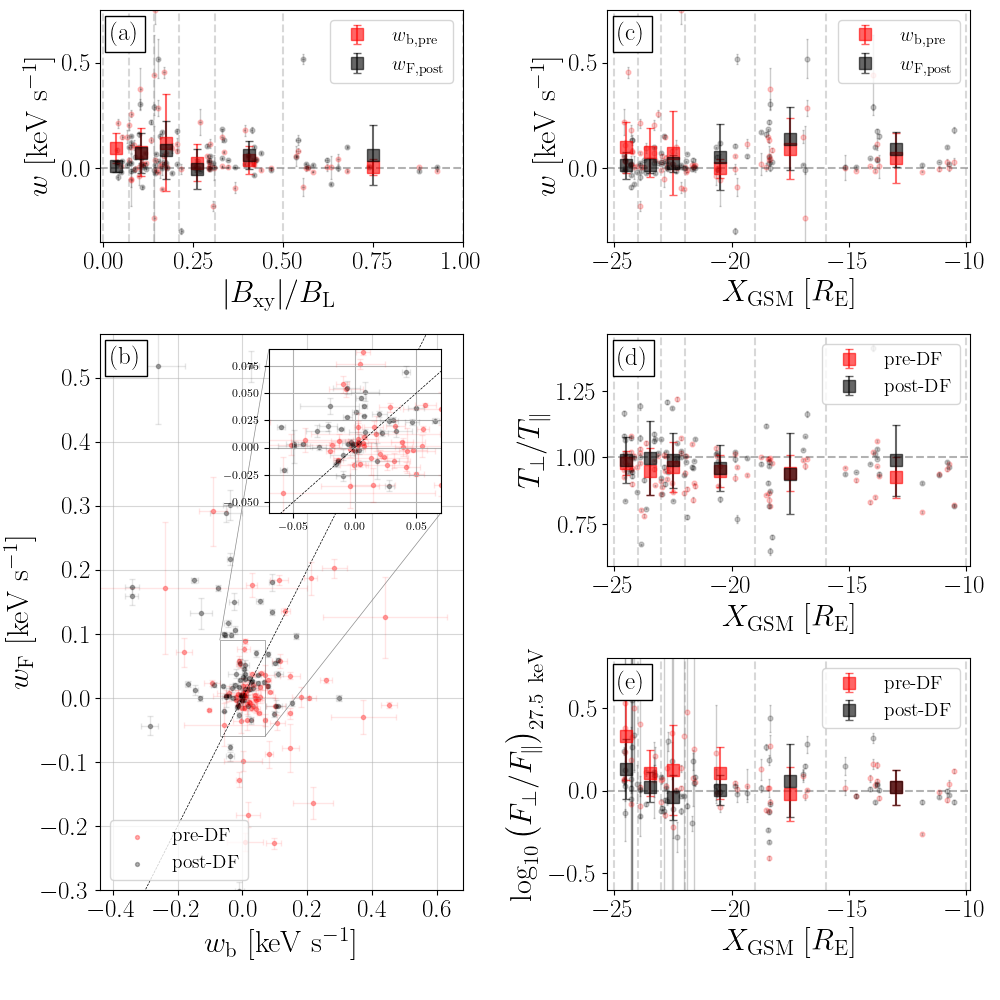

In [73]:
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
fontsize_ls=22
fontsize_leg = 14
fig = plt.figure(figsize=(10, 10))
# 3 rows × 2 columns grid
color_bet = "red"
color_fermi = "black"
# alpha = 0.3
s = 12
fontsize=22 
gs = gridspec.GridSpec(3, 2, height_ratios=[1, 1, 1], width_ratios=[1, 1], figure=fig, 
                       hspace=0.4, wspace = 0.4, top = 0.99, left = 0.1, right = 0.97)
# Panel a (top-left)
ax_a = fig.add_subplot(gs[0, 0])

# Panel b (left, spanning rows 2–3)
ax_b = fig.add_subplot(gs[1:, 0])  # span rows 1 and 2 (indexing from 0)

# Panel c (top-right)
ax_c = fig.add_subplot(gs[0, 1])

# Panel d (middle-right)
ax_d = fig.add_subplot(gs[1, 1])

# Panel e (bottom-right)
ax_e = fig.add_subplot(gs[2, 1])

axs = [ax_a, ax_b, ax_c, ax_d, ax_e]

axs[3].sharex(axs[2])
axs[4].sharex(axs[2])

axs[0].text( x = 0.03, y = 0.87,s =  "(a)", transform=axs[0].transAxes, bbox=dict(facecolor='white', edgecolor='black',))
axs[1].text( x = 0.03, y = 0.946,s =  "(b)", transform=axs[1].transAxes, bbox=dict(facecolor='white', edgecolor='black',))
make_labels(axs[2:], pos = [0.03, 0.87], pad = 2,  bbox=dict(facecolor='white', edgecolor='black',))
alpha = 0.2
alpha_0 = 0.2
alpha_1 = 0.6
alpha_2 = 0.7
axs[0].scatter(ps_distance_mean_before, w_betatron_max, c = color_bet, s = s,  alpha = alpha,)
axs[0].errorbar(ps_distance_mean_before, w_betatron_max, xerr = 1.2533*ps_distance_mean_before_sigma,yerr =  1.2533*w_betatron_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[0].errorbar(dps_binned, w_betatron_max_binned, yerr=w_betatron_max_binned_sem, marker = 's',
                fmt="o", capsize=3, color = "red", markersize = 8.5, label = "$w_{\mathrm{b, pre}}$", alpha = alpha_1)

axs[0].scatter(ps_distance_mean_before, w_fermi_max, c = color_fermi, s = s,alpha = alpha, )
axs[0].errorbar(ps_distance_mean_before, w_fermi_max, xerr = 1.2533*ps_distance_mean_before_sigma,yerr =  1.2533*w_fermi_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[0].errorbar(dps_binned, w_fermi_max_binned, yerr=w_fermi_max_binned_sem, marker = 's',
                fmt="o", capsize=3, color = "black", markersize = 8.5, label = "$w_{\mathrm{F, post}}$", alpha = alpha_1)

axs[0].set_ylabel("$w$ [$\mathrm{keV~s^{-1}}$]", fontsize=fontsize_ls)
axs[0].set_xlabel("$|B_{\mathrm{xy}}|/B_{\mathrm{L}}$", fontsize=fontsize_ls)
axs[0].legend(fontsize =  fontsize_leg, loc = "upper right",)
axs[0].set_xticks([0, 0.25, 0.5, 0.75, 1.0])

axs[2].scatter(xs_gsm, w_betatron_max, c = color_bet, s = s, alpha = alpha)
axs[2].errorbar(xs_gsm, w_betatron_max, yerr =  1.2533*w_betatron_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[2].errorbar(x_binned, wb_before_bin, yerr=wb_before_bin_sem, marker = 's',
                fmt="o", capsize=3, color = "red", markersize = 8.5, label = "$w_{\mathrm{b, pre}}$", alpha = alpha_1)

axs[2].scatter(xs_gsm, w_fermi_max, c = color_fermi, s = s, alpha = alpha)
axs[2].errorbar(xs_gsm, w_fermi_max, yerr =  1.2533*w_fermi_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[2].errorbar(x_binned, wf_after_bin, yerr=wf_after_bin_sem, marker = 's',
                fmt="o", capsize=3, color = "black", markersize = 8.5, label = "$w_{\mathrm{F, post}}$", alpha = alpha_1)

axs[2].set_xlabel("$X_{\mathrm{GSM}}$ [$R_{\mathrm{E}}$]", fontsize=fontsize_ls)
axs[2].legend(fontsize =  fontsize_leg, loc = "upper right",)
axs[2].set_ylabel("$w$ [$\mathrm{keV~s^{-1}}$]", fontsize=fontsize_ls)

axs[3].scatter(xs_gsm, t_ratio_before, c = color_bet, s = s, alpha = alpha)
axs[3].errorbar(xs_gsm, t_ratio_before, yerr =  1.2533*t_ratio_before_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[3].errorbar(x_binned, t_ratio_before_bin,yerr=t_ratio_before_bin_sem, marker = 's',
                fmt="o", capsize=3, color = "red", markersize = 8.5, label = "pre-DF", alpha = alpha_1)

axs[3].scatter(xs_gsm, t_ratio_after, c = color_fermi, s = s, alpha = alpha)
axs[3].errorbar(xs_gsm, t_ratio_after, yerr =  1.2533*t_ratio_after_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[3].errorbar(x_binned, t_ratio_after_bin, yerr=t_ratio_after_bin_sem, marker = 's',
                fmt="o", capsize=3, color = "black", markersize = 8.5, label = "post-DF", alpha = alpha_1)


axs[3].set_ylabel("$T_{\perp}/T_{\parallel}$", fontsize=fontsize_ls)
axs[3].set_xlabel("$X_{\mathrm{GSM}}$ [$R_{\mathrm{E}}$]", fontsize=fontsize_ls)
axs[3].legend(fontsize =  fontsize_leg, loc = "upper right",)

axs[4].scatter(xs_gsm, f_en_perp_para_ti_max_4_before, c = color_bet, s = s, alpha = alpha)
axs[4].errorbar(xs_gsm, f_en_perp_para_ti_max_4_before, yerr =  1.2533*f_en_perp_para_ti_max_4_before_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[4].errorbar(x_binned, f_en_perp_para_ti_max_4_before_bin, yerr=f_en_perp_para_ti_max_4_before_bin_sem, marker = 's',
                fmt="o", capsize=3, color = "red", markersize = 8.5, label = f"pre-DF", alpha = alpha_1)

axs[4].scatter(xs_gsm, f_en_perp_para_ti_max_4_after, c = color_fermi, s = s, alpha = alpha)
axs[4].errorbar(xs_gsm, f_en_perp_para_ti_max_4_after, yerr =  1.2533*f_en_perp_para_ti_max_4_after_sigma, fmt = "None",
             c  = "black", marker = None,lw = 1, zorder = 0, capsize = 1, alpha = alpha)
axs[4].errorbar(x_binned, f_en_perp_para_ti_max_4_after_bin, yerr=f_en_perp_para_ti_max_4_after_bin_sem, marker = 's',
                fmt="o", capsize=3, color = "black", markersize = 8.5, label = f"post-DF", alpha = alpha_1)

axs[4].set_xlabel("$X_{\mathrm{GSM}}$ [$R_{\mathrm{E}}$]", fontsize=fontsize_ls)
axs[4].set_ylabel("$\\log_{10}{\\left(F_{{\perp}}/F_{{\parallel}}\\right)_{\\rm 27.5~keV}}$", fontsize=fontsize_ls)
axs[4].legend(fontsize =  fontsize_leg, loc = "upper right",)

axs[0].axhline(0, color = "black", linestyle = "--", alpha = 0.3,)
axs[2].axhline(0, color = "black", linestyle = "--", alpha = 0.3,)
axs[3].axhline(1, color = "black", linestyle = "--", alpha = 0.3,)
axs[4].axhline(0, color = "black", linestyle = "--", alpha = 0.3, )

axs[1].scatter(w_betatron_max, w_fermi_max_before, c = "red", s = 9, alpha = 0.3)
axs[1].errorbar(w_betatron_max, w_fermi_max_before, xerr = 1.2533*w_betatron_sigma, yerr = 1.2533*w_fermi_max_before_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "red", alpha = 0.1)
axs[1].scatter(w_betatron_max_after, w_fermi_max, c = "black", s = 9, alpha = 0.3)
axs[1].errorbar(w_betatron_max_after, w_fermi_max, xerr = 1.2533*w_betatron_max_after_sigma, yerr = 1.2533*w_fermi_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "black", alpha = 0.1)

axs[1].grid(alpha= 0.5)
axs[1].set_xlabel("$w_{\\mathrm{b}}$ [$\\rm keV~s^{-1}$]", fontsize = fontsize_ls)
axs[1].set_ylabel("$w_{\\mathrm{F}}$ [$\\rm keV~s^{-1}$]", fontsize = fontsize_ls)
axs[1].plot([-1, 1], [-1, 1], color = "black", lw = 0.5, ls = "--")
axs[1].set_xlim(-0.44, 0.68)
axs[1].set_ylim(-0.3,  0.568)
axs[1].set_xticks([-0.4, -0.2, 0, 0.2, 0.4, 0.6])
axs[1].scatter([], [], c = "red", s = 8, alpha = 0.3, label = "pre-DF", )
axs[1].scatter([], [], c = "black", s = 8, alpha = 0.3, label = "post-DF", )
axs[1].legend(loc = "lower left", fontsize = fontsize_leg)

axins = inset_axes(axs[1], width="50%", height="30%", bbox_to_anchor=(0.025, 0.015, 0.95, 0.98), bbox_transform=axs[1].transAxes, )
axins.scatter(w_betatron_max, w_fermi_max_before, c = "red", s = 9, alpha = 0.3)
axins.errorbar(w_betatron_max, w_fermi_max_before, xerr = 1.2533*w_betatron_sigma, yerr = 1.2533*w_fermi_max_before_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "red", alpha = 0.1)
axins.scatter(w_betatron_max_after, w_fermi_max, c = "black", s = 9, alpha = 0.3)
axins.errorbar(w_betatron_max_after, w_fermi_max, xerr = 1.2533*w_betatron_max_after_sigma, yerr = 1.2533*w_fermi_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "black", alpha = 0.1)
axins.plot([-1, 1], [-1, 1], color = "black", lw = 0.5, ls = "--")
axins.grid()
axins.set_xlim(-0.07, 0.07)
axins.set_ylim(-0.06, 0.09)
axins.tick_params(axis='both', which='major', labelsize=8, )


for edge in x_bins:
    [ax.axvline(edge, color="gray", linestyle="--", alpha=0.3) for ax in axs[2:]]

axs[4].set_ylim([-0.6, 0.8])
axs[2].set_ylim([-0.35, 0.75])
axs[0].set_ylim([-0.35, 0.75])
for edge in dps_bins:
    axs[0].axvline(edge, color="gray", linestyle="--", alpha=0.3)

mark_inset(axs[1], axins, loc1=2, loc2=4, fc="none", ec="0.5", lw = 0.5, alpha = 0.9,)


# fig.savefig("paper_figs/figure_3_v3.png", bbox_inches = "tight", dpi = 500)

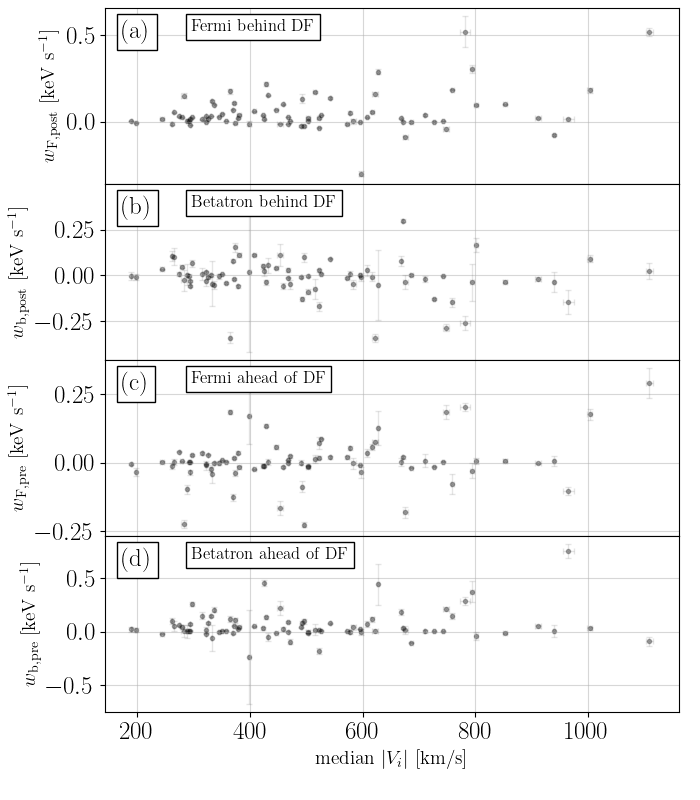

In [74]:
fig, axs = plt.subplots(4, figsize=(7, 8), sharex = True)
fig.subplots_adjust(hspace=0.0, top = 0.99, left = 0.15, right = 0.97)
axs[0].scatter(Vi_avg_mag_after, w_fermi_max, c = "black", s = 9, alpha = 0.3)
axs[0].errorbar(Vi_avg_mag_after, w_fermi_max, xerr = 1.2533*Vi_avg_mag_after_sigma, yerr = 1.2533*w_fermi_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "black", alpha = 0.1)
# axs[0].set_xlabel("$\\langle V_{i,x} \\rangle$ [km/s]", fontsize = fontsize_ls)
axs[0].set_ylabel("$w_{\\mathrm{F, post}}$ [$\\rm keV~s^{-1}$]", fontsize = 14)
axs[0].grid(alpha= 0.5)
axs[0].text(x = 0.15, y = 0.87, s = "Fermi behind DF", transform=axs[0].transAxes, bbox=dict(facecolor='white', edgecolor='black',), fontsize = 12,)
# axs[0].set_xlim(-100, 100)
# axs[0].set_ylim(-0.3,  0.568)
axs[0].scatter([], [], c = "black", s = 8, alpha = 0.3, label = "post-DF", )
# axs[0].legend(loc = "upper left", fontsize = fontsize_leg)

axs[1].scatter(Vi_avg_mag_after, w_betatron_max_after, c = "black", s = 9, alpha = 0.3)
axs[1].errorbar(Vi_avg_mag_after, w_betatron_max_after, xerr = 1.2533*Vi_avg_mag_after_sigma, yerr = 1.2533*w_betatron_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "black", alpha = 0.1)
# axs[1].set_xlabel("$\\langle V_{i,x} \\rangle$ [km/s]", fontsize = fontsize_ls)
axs[1].set_ylabel("$w_{\\mathrm{b, post}}$ [$\\rm keV~s^{-1}$]", fontsize = 14)
axs[1].grid(alpha= 0.5)
axs[1].text(x = 0.15, y = 0.87, s = "Betatron behind DF", transform=axs[1].transAxes, bbox=dict(facecolor='white', edgecolor='black',), fontsize = 12,)

axs[2].scatter(Vi_avg_mag_after, w_fermi_max_before, c = "black", s = 9, alpha = 0.3)
axs[2].errorbar(Vi_avg_mag_after, w_fermi_max_before, xerr = 1.2533*Vi_avg_mag_after_sigma, yerr = 1.2533*w_fermi_max_before_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "black", alpha = 0.1)
# axs[2].set_xlabel("$\\langle V_{i,x} \\rangle$ [km/s]", fontsize = fontsize_ls)
axs[2].set_ylabel("$w_{\\mathrm{F, pre}}$ [$\\rm keV~s^{-1}$]", fontsize = 14)
axs[2].grid(alpha= 0.5)
axs[2].text(x = 0.15, y = 0.87, s = "Fermi ahead of DF", transform=axs[2].transAxes, bbox=dict(facecolor='white', edgecolor='black',), fontsize = 12,)

axs[3].scatter(Vi_avg_mag_after, w_betatron_max, c = "black", s = 9, alpha = 0.3)
axs[3].errorbar(Vi_avg_mag_after, w_betatron_max, xerr = 1.2533*Vi_avg_mag_after_sigma, yerr = 1.2533*w_betatron_sigma, fmt = "None",
                elinewidth = 1, capsize = 2, color = "black", alpha = 0.1)
axs[3].set_xlabel("median $|V_{i}|$ [km/s]", fontsize = 14)
axs[3].set_ylabel("$w_{\\mathrm{b, pre}}$ [$\\rm keV~s^{-1}$]", fontsize = 14)
axs[3].grid(alpha= 0.5)
axs[3].text(x = 0.15, y = 0.87, s = "Betatron ahead of DF", transform=axs[3].transAxes, bbox=dict(facecolor='white', edgecolor='black',), fontsize = 12,)

make_labels(axs, pos = [0.03, 0.83],  bbox=dict(facecolor='white', edgecolor='black',))

fig.savefig("acc_terms_ion_outflow.png", bbox_inches = "tight", dpi = 500)